[<< Sommaire QC](../README.md) | [Précédent : QC-Py-44-Agent-Trading-Multi-LLM <<](./QC-Py-44-Agent-Trading-Multi-LLM.ipynb) | [Suivant : QC-Py-46-External-Etalon-FinanceBench >>](./QC-Py-46-External-Etalon-FinanceBench.ipynb)

# QC-Py-45 — Noyau de risque déterministe : stops, plafonds et coupe-circuit

**Série QuantConnect / Python — recherche, issue #24698 (étape 1).**

Le système Steward (Feng, Dai, Pan, Lau, Xu & Liu, *Governed Self-Evolution for Autonomous Investing: A Multi-Agent LLM System with an Invariant Core*, arXiv:2610.30557) confie à neuf agents LLM l'analyse, la décision et même la révision de leurs propres consignes. Mais tout cela tourne autour d'un **noyau invariant** — l'arithmétique des ordres, les règles de risque et les consignes des agents de discipline — qu'aucune auto-modification ne peut atteindre. Pour mesurer ce noyau indépendamment des agents, l'article le rejoue seul sur 2015-2026 (sa table 11) : les mêmes entrées hebdomadaires, avec et sans noyau, sur des entrées momentum et sur 50 politiques d'entrées tirées au hasard.

Ce carnet reprend **cette ablation seule**, sans aucun LLM, sur un univers de 23 ETF. La question : un jeu de règles de risque fixes, appliqué à des entrées qui n'ont aucun mérite, change-t-il le profil de risque ? Et à quel coût en rendement ?

## Ce que ce carnet mesure

1. Le **noyau complet** du papier : stop à 2 ATR sous le prix d'entrée, plafond de 40 % par groupe d'actifs, exposition d'au plus 90 % (10 positions à 9 %), aucun emprunt, coupe-circuit journalier à −3 %.
2. Ses **ablations** — chaque règle retirée tour à tour — et un **témoin à exposition égale** (9 % par ligne, sans aucune règle) qui sépare l'effet des règles de l'effet mécanique des 10 % de liquidités.
3. Un **verdict pré-enregistré** sur 50 graines d'entrées aléatoires (protocole publié sur l'issue #24698 avant le premier calcul) : écart de drawdown maximal, Diebold-Mariano sur la profondeur de drawdown, coût en Sharpe.

## Ce que ce carnet n'est pas

Ce n'est pas une réplication de Steward. L'article travaille sur les 80 actions américaines de son univers, et son noyau garde une couche d'agents qui décide des positions. Ici, l'univers est un panier d'ETF diversifiés, les entrées sont fixées par une règle (momentum ou hasard), et aucun modèle de langage n'intervient. Les ordres de grandeur ne sont donc pas comparables à ceux de l'article ; les **sens** des effets le sont.


## 1. Univers et données

23 ETF américains cotés depuis au moins 2014, répartis en quatre groupes ; le plafond de 40 % s'applique par groupe (le papier l'applique par secteur GICS).

| Groupe | ETF |
|---|---|
| Actions US | XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV, XLY, IWM |
| Actions hors US | EFA, EEM, EWJ, VGK |
| Obligations | TLT, IEF, LQD, HYG, TIP |
| Matières premières et immobilier | GLD, SLV, DBC, VNQ |

Les liquidités sont rémunérées au rendement de BIL (bons du Trésor américain à 1-3 mois) ; le papier rémunère de même les liquidités au rendement d'un ETF de bons du Trésor. SPY sert de référence. Données quotidiennes ajustées des dividendes (yfinance), fenêtre de mesure du 2015-01-02 au 2026-10-30 ; l'année 2014 ne sert qu'à amorcer l'ATR et le momentum. Le carnet requiert un accès réseau à l'exécution.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf

GROUPES = {
    "Actions US": ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY", "IWM"],
    "Actions hors US": ["EFA", "EEM", "EWJ", "VGK"],
    "Obligations": ["TLT", "IEF", "LQD", "HYG", "TIP"],
    "Matieres premieres et immobilier": ["GLD", "SLV", "DBC", "VNQ"],
}
TICKERS = [t for g in GROUPES.values() for t in g]
CASH, BENCH = "BIL", "SPY"
DEBUT, FIN = "2015-01-02", "2026-10-30"

raw = yf.download(TICKERS + [CASH, BENCH], start="2014-01-01", end="2026-10-31",
                  auto_adjust=True, progress=False)
O, H, L, C = (raw[k][TICKERS] for k in ("Open", "High", "Low", "Close"))
dates = C.loc[DEBUT:FIN].index
print(f"{len(TICKERS)} ETF + {CASH} + {BENCH}, {len(dates)} seances du {dates[0].date()} au {dates[-1].date()}")
print("valeurs manquantes sur la fenetre :", int(raw.loc[DEBUT:FIN].isna().sum().sum()))
print("lignes par groupe :", {g: len(v) for g, v in GROUPES.items()})

23 ETF + BIL + SPY, 2975 seances du 2015-01-02 au 2026-10-30
valeurs manquantes sur la fenetre : 0
lignes par groupe : {'Actions US': 10, 'Actions hors US': 4, 'Obligations': 5, 'Matieres premieres et immobilier': 4}


### Lecture

2 975 séances, aucune valeur manquante. Avec 10 positions à 9 %, le plafond de 40 % ne peut mordre que sur deux groupes : les actions US, dès que 5 de leurs 10 ETF sont retenus (45 %), et les obligations, si leurs 5 ETF le sont tous. Les deux autres groupes comptent 4 ETF chacun, soit 36 % au plus : le plafond ne les touche jamais.

## 2. Le moteur de simulation

Une seule boucle journalière rejoue toutes les variantes. Chaque séance :

1. les liquidités sont rémunérées au rendement du jour de BIL ;
2. le premier jour de bourse de la semaine, la fonction d'entrées désigne 10 positions ; les ordres partent **à l'ouverture**, sur des signaux calculés à la **clôture précédente** (momentum, ATR) : aucune donnée du jour n'entre dans la décision ;
3. ventes d'abord, achats ensuite, réduits si les liquidités ne suffisent pas : jamais d'emprunt ;
4. à l'ouverture d'une ligne, son stop est posé à 2 ATR(14) sous le prix d'ouverture, et il ne bouge plus tant que la ligne est détenue ;
5. si le plus bas du jour touche le stop, la ligne sort au plus bas de l'ouverture et du stop (un gap baissier sort donc à l'ouverture), puis reste à plat jusqu'au rebalancement suivant ;
6. si la valeur du portefeuille perd 3 % ou plus sur la séance, tout est liquidé à la clôture, et les lignes reviennent à l'ouverture suivante.

Frais : 5 points de base par côté. Les six variantes ne diffèrent que par quatre réglages : le poids par ligne (10 % ou 9 %), les stops, le plafond de groupe et le coupe-circuit.

In [2]:
prev_c = C.shift(1)
true_range = pd.concat([H - L, (H - prev_c).abs(), (L - prev_c).abs()]).groupby(level=0).max()
ATR14 = true_range.rolling(14).mean()
MOM = C.shift(5) / C.shift(131) - 1          # 126 seances en sautant les 5 dernieres
cash_ret = raw["Close"][CASH].pct_change().fillna(0.0).loc[dates].values

semaine = dates.to_series().dt.to_period("W")
REBAL = np.asarray(semaine.ne(semaine.shift(1)).values)   # premier jour de bourse de la semaine
GRP = np.array([next(i for i, g in enumerate(GROUPES.values()) if t in g) for t in TICKERS])
N = len(TICKERS)
Oa, La, Ca = (X.loc[dates].values for X in (O, L, C))
atr_prev = ATR14.shift(1).loc[dates].values   # signaux pris sur la cloture precedente
mom_prev = MOM.shift(1).loc[dates].values

VARIANTES = {
    # nom : (poids par ligne, stops, plafond de groupe, coupe-circuit)
    "Sans noyau":              (0.10, False, False, False),
    "Exposition 90 % seule":   (0.09, False, False, False),
    "Stops seuls":             (0.10, True,  False, False),
    "Noyau sans stops":        (0.09, False, True,  True),
    "Noyau sans coupe-circuit": (0.09, True,  True,  False),
    "Noyau complet":           (0.09, True,  True,  True),
}


def poids_cibles(lignes, w_ligne, plafond):
    w = np.zeros(N)
    w[lignes] = w_ligne
    if plafond:
        for g in np.unique(GRP):
            m = (GRP == g) & (w > 0)
            if w[m].sum() > 0.40 + 1e-12:
                w[m] *= 0.40 / w[m].sum()     # reduction au prorata dans le groupe
    return w


def simuler(choix, variante, frais=0.0005, mult_stop=2.0, seuil_cc=-0.03, rearmer_stop=False):
    """Rejoue une suite d'entrees hebdomadaires sous une variante du noyau.

    choix(t) rend les indices des 10 lignes visees au rebalancement du jour t.
    Retourne la valeur du portefeuille a chaque cloture et un journal de controle.
    """
    w_ligne, stops, plafond, coupe = VARIANTES[variante] if isinstance(variante, str) else variante
    cash, parts = 1.0, np.zeros(N)
    stop = np.full(N, np.nan)
    stoppee = np.zeros(N, bool)
    lignes, reentree = None, False
    valeur = np.empty(len(dates))
    veille = 1.0
    log = dict(rotation=0.0, stops=0, coupures=0, ouvertures=[], poids_groupe_max=0.0, cash_min=1.0)
    for t in range(len(dates)):
        o, l, c = Oa[t], La[t], Ca[t]
        if t > 0:
            cash *= 1 + cash_ret[t]                       # liquidites remunerees au taux de BIL
        if REBAL[t]:
            lignes = choix(t)
            stoppee[:] = False
        if REBAL[t] or reentree:
            reentree = False
            w = poids_cibles(lignes, w_ligne, plafond)
            w[stoppee] = 0.0                              # une ligne stoppee reste a plat jusqu'au rebalancement
            v_ouv = cash + np.sum(parts * o)
            if REBAL[t]:
                log["ouvertures"].append((t, v_ouv))
            ecart = w * v_ouv / o - parts
            vente = np.minimum(ecart, 0.0)
            cash -= np.sum(vente * o) * (1 - frais)
            log["rotation"] += -np.sum(vente * o)
            parts += vente
            achat = np.maximum(ecart, 0.0)
            besoin = np.sum(achat * o) * (1 + frais)
            if besoin > cash:
                achat *= cash / besoin                    # jamais d'emprunt
            cash -= np.sum(achat * o) * (1 + frais)
            log["rotation"] += np.sum(achat * o)
            ouverte = (achat > 0) & (parts <= 0)
            parts += achat
            if stops:
                niveau = o - mult_stop * atr_prev[t]
                if rearmer_stop:                          # variante : stop recale a chaque rebalancement
                    stop = np.where(parts > 0, niveau, np.nan)
                else:                                     # papier : stop fixe a l'ouverture de la ligne
                    stop = np.where(ouverte, niveau, np.where(parts > 0, stop, np.nan))
            pg = np.bincount(GRP, weights=parts * o, minlength=GRP.max() + 1) / (cash + np.sum(parts * o))
            log["poids_groupe_max"] = max(log["poids_groupe_max"], pg.max())
        if stops:
            touche = (parts > 0) & (l <= stop)
            if touche.any():
                prix = np.minimum(o, stop)                # au plus bas de l'ouverture et du stop
                produit = np.sum(parts[touche] * prix[touche])
                cash += produit * (1 - frais)
                log["rotation"] += produit
                parts[touche] = 0.0
                stop[touche] = np.nan
                stoppee |= touche
                log["stops"] += int(touche.sum())
        v = cash + np.sum(parts * c)
        if coupe and v / veille - 1 <= seuil_cc and parts.sum() > 0:
            produit = np.sum(parts * c)                   # liquidation a la cloture
            cash += produit * (1 - frais)
            log["rotation"] += produit
            parts[:] = 0.0
            stop[:] = np.nan
            reentree = True                               # retour a l'ouverture suivante
            log["coupures"] += 1
            v = cash
        log["cash_min"] = min(log["cash_min"], cash)
        valeur[t] = v
        veille = v
    return valeur, log


def mesures(valeur):
    r = np.diff(valeur) / valeur[:-1]
    dd = valeur / np.maximum.accumulate(valeur) - 1
    return dict(CAGR=valeur[-1] ** (252 / len(valeur)) - 1,
                Sharpe=r.mean() / r.std() * np.sqrt(252),
                MaxDD=dd.min()), dd


def entrees_momentum(t):
    return np.argsort(-mom_prev[t])[:10]


def entrees_aleatoires(graine):
    rng = np.random.default_rng(graine)
    return lambda t: rng.choice(N, 10, replace=False)


print("moteur pret :", len(VARIANTES), "variantes,", int(REBAL.sum()), "rebalancements hebdomadaires")

moteur pret : 6 variantes, 618 rebalancements hebdomadaires


### Lecture

618 rebalancements hebdomadaires sur la fenêtre. Avant de mesurer quoi que ce soit avec ce moteur, il faut vérifier qu'il calcule ce qu'on croit.

## 3. Contrôles du moteur

Trois contrôles, chacun contre une référence extérieure à la boucle :

1. sans règle et sans frais, un panier fixe de 10 positions à 10 % doit valoir, à chaque ouverture de rebalancement, exactement le produit des rendements moyens d'ouverture à ouverture — un calcul direct sur les prix, sans boucle ;
2. le plafond de groupe doit tenir quand on impose les 10 ETF d'actions US, le cas où il mord le plus ;
3. les liquidités ne doivent jamais passer sous zéro, dans aucune variante.

In [3]:
# 1. Sans regle et sans frais, le moteur doit rendre exactement un portefeuille equipondere
#    rebalance chaque semaine a l'ouverture, calcule ici directement sur les prix.
fixes = np.array([TICKERS.index(t) for t in ["XLK", "XLV", "XLP", "XLU", "EFA", "EEM", "TLT", "IEF", "GLD", "VNQ"]])
val, log = simuler(lambda t: fixes, (0.10, False, False, False), frais=0.0)
t_reb = [t for t, _ in log["ouvertures"]]
v_moteur = np.array([v for _, v in log["ouvertures"]])
rel = Oa[t_reb][:, fixes]
v_direct = np.concatenate([[1.0], np.cumprod(np.mean(rel[1:] / rel[:-1], axis=1))])
print(f"1. Moteur sans regle vs calcul direct sur les prix : ecart max = {np.max(np.abs(v_moteur - v_direct)):.2e}")

# 2. Le plafond de groupe doit tenir a chaque rebalancement : on rejoue la variante complete
#    sur des entrees qui concentrent les 10 lignes d'actions US, cas ou il mord le plus.
us = np.array([i for i, t in enumerate(TICKERS) if t in GROUPES["Actions US"]])
val, log = simuler(lambda t: us, "Noyau complet")
print(f"2. Dix lignes d'actions US : poids de groupe max apres rebalancement = {log['poids_groupe_max']:.4f} (plafond 0.40)")

# 3. Jamais d'emprunt : les liquidites ne passent jamais sous zero, quelle que soit la variante.
cmin = min(simuler(entrees_aleatoires(g), nom)[1]["cash_min"] for g in range(5) for nom in VARIANTES)
print(f"3. Liquidites minimales sur 5 graines x {len(VARIANTES)} variantes : {cmin:.2e}")

1. Moteur sans regle vs calcul direct sur les prix : ecart max = 9.33e-15
2. Dix lignes d'actions US : poids de groupe max apres rebalancement = 0.4001 (plafond 0.40)


3. Liquidites minimales sur 5 graines x 6 variantes : -6.67e-16


### Lecture

1. L'écart maximal est de l'ordre de 1e-14 : la boucle rend le calcul direct à la précision machine près. La comptabilité des parts, des ventes et des achats est juste.
2. Le poids du groupe culmine à 0,4001 au lieu de 0,40 : les poids cibles sont calculés sur la valeur à l'ouverture, et les frais d'achat réduisent cette valeur d'environ un dix-millième. Le plafond tient.
3. Les liquidités minimales sont un résidu d'arrondi de l'ordre de −1e-15 : aucune variante n'emprunte.

## 4. Entrées momentum

Premier jeu d'entrées : chaque semaine, les 10 ETF au meilleur rendement sur 126 séances, en sautant les 5 dernières (pour éviter le retournement de court terme). C'est une règle qui a un mérite propre, mais c'est **un seul chemin** : on le lit comme un exemple, sans verdict.

In [4]:
spy = raw["Close"][BENCH].loc[dates].values
res_mom, dd_mom = {}, {}
for nom in VARIANTES:
    val, log = simuler(entrees_momentum, nom)
    m, dd = mesures(val)
    res_mom[nom] = dict(m, stops=log["stops"], coupures=log["coupures"], rotation=log["rotation"] / (len(dates) / 252))
    dd_mom[nom] = dd
m_spy, dd_mom["SPY"] = mesures(spy / spy[0])
res_mom["SPY (reference)"] = dict(m_spy, stops=0, coupures=0, rotation=0.0)
tab_mom = pd.DataFrame(res_mom).T
fmt = tab_mom.copy()
for k in ("CAGR", "MaxDD"):
    fmt[k] = (100 * fmt[k]).map("{:+.1f} %".format)
fmt["Sharpe"] = fmt["Sharpe"].map("{:.2f}".format)
fmt["rotation"] = fmt["rotation"].map("{:.1f} x/an".format)
fmt[["stops", "coupures"]] = fmt[["stops", "coupures"]].astype(int)
print("Entrees momentum (top 10 sur 126 j hors 5 derniers), 2015-2026, 5 bp par cote")
print(fmt.to_string())

Entrees momentum (top 10 sur 126 j hors 5 derniers), 2015-2026, 5 bp par cote
                             CAGR Sharpe    MaxDD  stops  coupures   rotation
Sans noyau                 +7.1 %   0.60  -29.3 %      0         0  18.1 x/an
Exposition 90 % seule      +6.6 %   0.61  -26.6 %      0         0  15.9 x/an
Stops seuls                +7.5 %   0.68  -17.5 %    480         0  27.0 x/an
Noyau sans stops           +7.4 %   0.76  -23.1 %      0         6  18.1 x/an
Noyau sans coupe-circuit   +7.4 %   0.82  -13.2 %    480         0  23.4 x/an
Noyau complet              +7.1 %   0.79  -14.1 %    497         4  24.8 x/an
SPY (reference)           +13.5 %   0.81  -33.7 %      0         0   0.0 x/an


### Lecture

| | Sans noyau | Noyau complet |
|---|---|---|
| CAGR | +7,1 % | +7,1 % |
| Sharpe | 0,60 | 0,79 |
| Drawdown maximal | −29,3 % | −14,1 % |

Le noyau divise le drawdown maximal par deux sans coûter de rendement, et le Sharpe passe de 0,60 à 0,79. Les ablations disent d'où vient l'effet :

- **les stops portent l'essentiel** : à eux seuls, ils ramènent le drawdown à −17,5 % ; le noyau privé de ses stops (plafond, exposition, coupe-circuit) s'arrête à −23,1 % ;
- **le coupe-circuit ne sert presque à rien ici** : le noyau sans coupe-circuit fait même un peu mieux (−13,2 %) que le noyau complet. Sur un panier d'ETF diversifiés, une séance à −3 % pour tout le portefeuille est rare : 4 coupures en près de douze ans ;
- **le témoin à 9 % n'explique qu'une petite part** : garder 10 % de liquidités ramène le drawdown de −29,3 % à −26,6 %.

Le prix : la rotation (volume échangé par an, en multiples du capital de départ) passe de 18 à 25, et chacun des 497 stops paie des frais. SPY, sur la même fenêtre, fait nettement mieux en rendement (+13,5 %) avec un Sharpe voisin (0,81) et un drawdown de −33,7 % : le noyau ne transforme pas un panier d'ETF en indice d'actions américaines, il borne ce qu'il perd.

Le graphique suivant montre où se font les écarts.

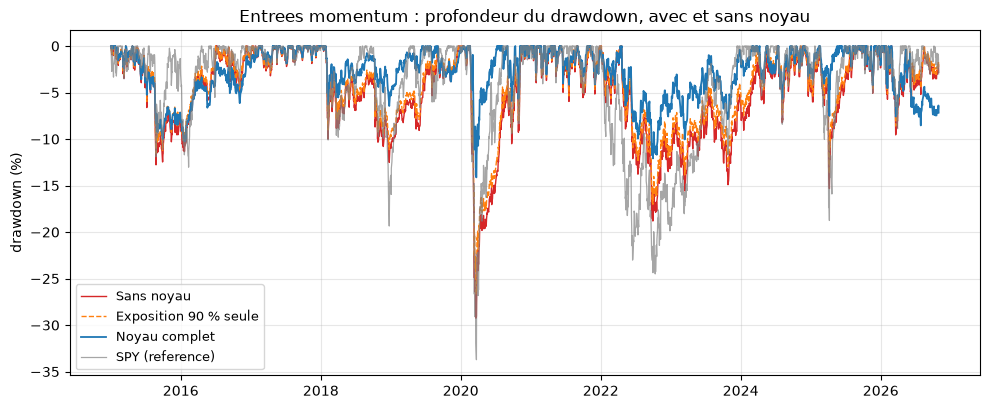

Point le plus bas du drawdown dans l'annee, et niveau a la derniere seance, en %
                Sans noyau  Exposition 90 % seule  Noyau complet   SPY
Date                                                                  
2018                 -12.5                  -11.1           -6.4 -19.3
2020                 -29.3                  -26.6          -14.1 -33.7
2022                 -18.8                  -17.0          -12.1 -24.5
2026                  -9.6                   -8.6           -8.5  -8.9
fin de fenetre        -2.8                   -2.4           -7.2  -3.0


In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4.2))
for nom, style in (("Sans noyau", dict(color="tab:red", lw=1.0)),
                   ("Exposition 90 % seule", dict(color="tab:orange", lw=1.0, ls="--")),
                   ("Noyau complet", dict(color="tab:blue", lw=1.3)),
                   ("SPY", dict(color="grey", lw=0.9, alpha=0.7))):
    ax.plot(dates, 100 * dd_mom[nom], label=nom if nom != "SPY" else "SPY (reference)", **style)
ax.set_ylabel("drawdown (%)")
ax.set_title("Entrees momentum : profondeur du drawdown, avec et sans noyau")
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

noms = ("Sans noyau", "Exposition 90 % seule", "Noyau complet", "SPY")
creux = pd.DataFrame({nom: pd.Series(100 * dd_mom[nom], index=dates).groupby(dates.year).min() for nom in noms})
creux = creux.loc[[2018, 2020, 2022, 2026]]
creux.index = creux.index.astype(str)
creux.loc["fin de fenetre"] = [100 * dd_mom[nom][-1] for nom in noms]
print("Point le plus bas du drawdown dans l'annee, et niveau a la derniere seance, en %")
print(creux.round(1).to_string())

### Lecture

Le creux de mars 2020 est celui que le noyau écrête le plus : −29,3 % sans noyau, −14,1 % avec. Même schéma en 2022 (−18,8 % contre −12,1 %) et en 2018 (−12,5 % contre −6,4 %). La courbe du témoin à 9 % (tirets) suit celle sans noyau presque partout : ce n'est pas la poche de liquidités qui protège, ce sont les sorties sur stop pendant les chutes rapides.

L'année 2026 montre l'autre face. Le creux y est du même ordre pour les trois variantes (−9,6 %, −8,6 % et −8,5 %) : le noyau n'écrête pas cet épisode. Et à la dernière séance, le noyau reste à −7,2 % de son plus haut, quand les deux autres sont revenus vers −2,5 %. Une sortie sur stop vend pendant la baisse et ne rachète qu'au rebalancement suivant : si le marché repart entre-temps, la remontée se fait sans les lignes vendues. Ce carnet ne mesure pas si c'est bien ce mécanisme qui explique le retard de 2026. Ce qui est mesuré, sur ce seul chemin : le noyau écrête les trois grands creux, et il peut aussi finir plus loin de son plus haut que les variantes sans noyau.

## 5. Entrées aléatoires : 50 graines

Un seul chemin momentum ne prouve rien : ses stops ont pu avoir de la chance. Le papier répond par des entrées **sans aucun mérite** : chaque semaine, 10 positions tirées au hasard. Pour une graine donnée, les six variantes reçoivent exactement les mêmes tirages ; seul le noyau change. 50 graines, 300 simulations.

In [6]:
GRAINES = range(50)
lignes, dd_alea, val_alea = [], {}, {}
for g in GRAINES:
    for nom in VARIANTES:
        val, log = simuler(entrees_aleatoires(g), nom)
        m, dd = mesures(val)
        lignes.append(dict(graine=g, variante=nom, **m, stops=log["stops"], coupures=log["coupures"]))
        if nom in ("Sans noyau", "Exposition 90 % seule", "Noyau complet"):
            dd_alea[(g, nom)] = dd
            val_alea[(g, nom)] = val
alea = pd.DataFrame(lignes)
q = alea.groupby("variante")[["CAGR", "Sharpe", "MaxDD"]].quantile([0.05, 0.5, 0.95]).unstack()
tab = pd.DataFrame({
    k: [f"{100 * q.loc[v, (k, 0.5)]:+.1f} % [{100 * q.loc[v, (k, 0.05)]:+.1f} ; {100 * q.loc[v, (k, 0.95)]:+.1f}]"
        if k != "Sharpe" else
        f"{q.loc[v, (k, 0.5)]:.2f} [{q.loc[v, (k, 0.05)]:.2f} ; {q.loc[v, (k, 0.95)]:.2f}]"
        for v in VARIANTES] for k in ("CAGR", "Sharpe", "MaxDD")}, index=list(VARIANTES))
tab["stops (med.)"] = alea.groupby("variante")["stops"].median().reindex(list(VARIANTES)).astype(int)
tab["coupures (med.)"] = alea.groupby("variante")["coupures"].median().reindex(list(VARIANTES)).astype(int)
print("Entrees aleatoires, 50 graines : mediane [5 % ; 95 %]")
print(tab.to_string())

Entrees aleatoires, 50 graines : mediane [5 % ; 95 %]
                                          CAGR              Sharpe                    MaxDD  stops (med.)  coupures (med.)
Sans noyau                +5.8 % [+4.3 ; +8.0]  0.52 [0.39 ; 0.68]  -28.1 % [-31.7 ; -24.2]             0                0
Exposition 90 % seule     +5.5 % [+4.1 ; +7.4]  0.53 [0.40 ; 0.70]  -25.5 % [-28.9 ; -22.0]             0                0
Stops seuls               +6.7 % [+5.2 ; +8.3]  0.65 [0.52 ; 0.78]  -18.8 % [-24.0 ; -15.7]          1070                0
Noyau sans stops          +5.1 % [+3.6 ; +6.7]  0.54 [0.39 ; 0.68]  -22.9 % [-27.9 ; -19.3]             0                7
Noyau sans coupe-circuit  +5.8 % [+4.5 ; +6.9]  0.66 [0.51 ; 0.78]  -16.4 % [-20.8 ; -13.4]          1070                0
Noyau complet             +5.8 % [+4.3 ; +6.8]  0.65 [0.50 ; 0.77]  -16.4 % [-20.8 ; -13.4]          1070                3


### Lecture

Médianes sur 50 graines, entre crochets les 5e et 95e centiles :

- **sans noyau**, drawdown maximal −28,1 % ; **noyau complet**, −16,4 %. Les deux intervalles ne se recouvrent pas : le 5e centile du noyau (−20,8 %) reste moins profond que le 95e centile sans noyau (−24,2 %) ;
- le Sharpe passe de 0,52 à 0,65, le CAGR reste à 5,8 % des deux côtés ;
- **les stops seuls** font presque tout (−18,8 %, Sharpe 0,65) et relèvent même le CAGR (+6,7 %) : sortir des lignes qui chutent et garder leur produit en liquidités rémunérées coûte moins que de les subir ;
- **le noyau sans stops** (−22,9 %) fait mieux que le témoin à 9 % (−25,5 %), mais au prix du CAGR le plus bas du tableau (+5,1 %) : 7 coupures médianes, chacune payée deux fois en frais sur tout le portefeuille ;
- **le noyau sans coupe-circuit** a la même médiane que le noyau complet (−16,4 %).

Même lecture qu'en momentum : sur cet univers, ce sont les stops qui font le travail. Reste à savoir si l'écart est assez net pour passer le protocole pré-enregistré.

## 6. Verdict pré-enregistré

Le protocole a été publié sur l'issue #24698 avant le premier calcul. Chaque comparaison a trois jambes :

- **A** : l'écart de drawdown maximal (en points, positif = noyau moins profond) a une moyenne d'au moins 2 écarts-types inter-graines, et il est positif sur au moins 45 graines sur 50 ;
- **B** : un test de Diebold-Mariano (organe du dépôt, `ML-Training-Pipeline/scripts/dm_test.py`) sur la profondeur de drawdown jour par jour, perte quadratique, correction HAC à 21 séances : p médian < 0,05, en faveur du noyau ;
- **C** : le Sharpe médian ne baisse pas de plus de 0,05.

**BEATS** si A, B et C tiennent ; **NO BEATS** si le drawdown ne baisse pas en médiane, ou si le Sharpe baisse sur au moins 48 graines ; **INCONCLUSIVE** sinon. Deux comparaisons : contre « Sans noyau », la question du papier, et contre le témoin à exposition égale, la question de ce carnet — les règles font-elles mieux qu'une simple poche de liquidités ?

In [7]:
# Organe Diebold-Mariano du depot : ML-Training-Pipeline/scripts/dm_test.py
_cands = [d / sub for d in [Path.cwd(), *Path.cwd().parents]
          for sub in ("ML-Training-Pipeline/scripts", "MyIA.AI.Notebooks/QuantConnect/ML-Training-Pipeline/scripts")]
sys.path.insert(0, str(next(c for c in _cands if (c / "dm_test.py").exists())))
from dm_test import diebold_mariano_test


def paire(a, b):
    pa = alea[alea.variante == a].set_index("graine")
    pb = alea[alea.variante == b].set_index("graine")
    d_dd = 100 * (pa.MaxDD - pb.MaxDD)               # en points ; positif = drawdown moindre pour a
    d_sh = pa.Sharpe - pb.Sharpe
    d_cagr = 100 * (pa.CAGR - pb.CAGR)
    dm = [diebold_mariano_test(dd_alea[(g, a)], dd_alea[(g, b)], loss_fn="mse", max_lag=21) for g in GRAINES]
    p = np.array([r.p_value for r in dm])
    s = np.array([r.mean_loss_diff for r in dm])
    A = (d_dd.mean() >= 2 * d_dd.std()) and (d_dd > 0).sum() >= 45
    B = (np.median(p) < 0.05) and (np.median(s) < 0)
    Cc = d_sh.median() >= -0.05
    if A and B and Cc:
        verdict = "BEATS"
    elif d_dd.median() <= 0 or (d_sh < 0).sum() >= 48:
        verdict = "NO BEATS"
    else:
        verdict = "INCONCLUSIVE"
    print(f"{a} contre {b}")
    print(f"  A  dMaxDD = {d_dd.mean():+.2f} pt, sigma inter-graines {d_dd.std():.2f} "
          f"(ratio {d_dd.mean() / d_dd.std():.1f}), positif sur {(d_dd > 0).sum()}/50 -> {'oui' if A else 'non'}")
    print(f"  B  DM (perte mse sur la profondeur de drawdown, lag 21) : p median = {np.median(p):.2g}, "
          f"ecart de perte median {np.median(s):+.2e} -> {'oui' if B else 'non'}")
    print(f"  C  dSharpe median = {d_sh.median():+.3f} [{d_sh.quantile(0.05):+.3f} ; {d_sh.quantile(0.95):+.3f}] -> {'oui' if Cc else 'non'}")
    print(f"  cout : dCAGR median = {d_cagr.median():+.2f} pt [{d_cagr.quantile(0.05):+.2f} ; {d_cagr.quantile(0.95):+.2f}]")
    print(f"  verdict : {verdict}")
    p252 = np.median([diebold_mariano_test(dd_alea[(g, a)], dd_alea[(g, b)], loss_fn="mse", max_lag=252).p_value
                      for g in GRAINES])
    print(f"  sensibilite, hors verdict : p median avec un lag HAC de 252 = {p252:.2g}")
    return verdict


v_principal = paire("Noyau complet", "Sans noyau")
print()
v_temoin = paire("Noyau complet", "Exposition 90 % seule")

Noyau complet contre Sans noyau
  A  dMaxDD = +11.17 pt, sigma inter-graines 2.82 (ratio 4.0), positif sur 50/50 -> oui
  B  DM (perte mse sur la profondeur de drawdown, lag 21) : p median = 1e-08, ecart de perte median -2.22e-03 -> oui
  C  dSharpe median = +0.138 [+0.066 ; +0.207] -> oui
  cout : dCAGR median = +0.06 pt [-0.99 ; +0.69]
  verdict : BEATS
  sensibilite, hors verdict : p median avec un lag HAC de 252 = 0.0066

Noyau complet contre Exposition 90 % seule
  A  dMaxDD = +8.61 pt, sigma inter-graines 2.72 (ratio 3.2), positif sur 50/50 -> oui
  B  DM (perte mse sur la profondeur de drawdown, lag 21) : p median = 4.1e-05, ecart de perte median -1.27e-03 -> oui
  C  dSharpe median = +0.122 [+0.049 ; +0.190] -> oui
  cout : dCAGR median = +0.33 pt [-0.58 ; +0.93]
  verdict : BEATS


  sensibilite, hors verdict : p median avec un lag HAC de 252 = 0.029


### Lecture

Les deux comparaisons sortent **BEATS** :

| | contre Sans noyau | contre Exposition 90 % seule |
|---|---|---|
| A : écart de drawdown moyen | +11,2 pt (4,0 σ), positif sur 50/50 | +8,6 pt (3,2 σ), positif sur 50/50 |
| B : Diebold-Mariano, p médian (lag 21) | 1e-08 | 4e-05 |
| C : écart de Sharpe médian | +0,14 | +0,12 |
| Écart de CAGR médian | +0,06 pt | +0,33 pt |

Le noyau ne fait pas que remplacer 10 % d'actifs par des liquidités : contre le témoin à exposition égale, il garde 8,6 points de drawdown d'avance en moyenne, et l'écart est positif sur chacune des 50 graines.

Une réserve sur la jambe B. La profondeur de drawdown est une série extrêmement persistante — un creux dure des mois — et une correction HAC à 21 séances sous-estime sa variance. Avec 252 séances (hors protocole, affiché pour la sensibilité), le p médian monte à environ 0,007 et 0,03 : toujours sous 0,05, mais bien plus fragile. La jambe A, qui compare 50 chemins, est la plus solide des trois.

## 7. Par pli

Un drawdown maximal sur près de douze ans peut tenir à un seul épisode. On découpe la fenêtre en 5 plis contigus de même longueur, et on relit le drawdown maximal à l'intérieur de chacun, sur les mêmes trajectoires.

In [8]:
plis = np.array_split(np.arange(len(dates)), 5)
rows = []
for k, idx in enumerate(plis):
    lab = f"{dates[idx[0]].date()} -> {dates[idx[-1]].date()}"
    for nom in ("Sans noyau", "Exposition 90 % seule", "Noyau complet"):
        dd_pli = []
        for g in GRAINES:
            v = val_alea[(g, nom)][idx]              # valeur du portefeuille relue a l'interieur du pli
            dd_pli.append((v / np.maximum.accumulate(v) - 1).min())
        rows.append(dict(pli=f"{k + 1} ({lab})", variante=nom, MaxDD=100 * np.median(dd_pli)))
plis_tab = pd.DataFrame(rows).pivot(index="pli", columns="variante", values="MaxDD")[["Sans noyau", "Exposition 90 % seule", "Noyau complet"]]
print("Drawdown maximal median par pli (50 graines, en %)")
print(plis_tab.round(1).to_string())

Drawdown maximal median par pli (50 graines, en %)
variante                      Sans noyau  Exposition 90 % seule  Noyau complet
pli                                                                           
1 (2015-01-02 -> 2017-05-12)       -15.9                  -14.4          -13.3
2 (2017-05-15 -> 2019-09-24)       -16.3                  -14.6          -10.3
3 (2019-09-25 -> 2022-02-02)       -27.9                  -25.4          -13.0
4 (2022-02-03 -> 2024-06-17)       -20.0                  -18.1          -14.9
5 (2024-06-18 -> 2026-10-30)       -11.4                  -10.2           -7.1


### Lecture

Le noyau réduit le drawdown médian dans les cinq plis. L'écart est le plus net au pli 3 (septembre 2019 → février 2022, qui contient mars 2020) : −27,9 % sans noyau, −13,0 % avec. Au pli 1 (2015 → mai 2017, sans chute brutale), il n'est que d'environ 2,5 points. Le noyau agit surtout dans les chutes rapides, celles que des stops à 2 ATR sont faits pour attraper.

## 8. Comparaison avec le papier

| | Papier (80 actions US) | Ce carnet (23 ETF) |
|---|---|---|
| Drawdown médian, entrées aléatoires | −37 % → −28 % | −28,1 % → −16,4 % |
| Drawdown, entrées momentum | −61 % → −33 % | −29,3 % → −14,1 % |
| Graines où le drawdown baisse | 50 sur 50 | 50 sur 50 |
| Sharpe médian, entrées aléatoires | 0,81 → 0,82 | 0,52 → 0,65 |
| Sharpe, entrées momentum | 1,15 → 1,30 | 0,60 → 0,79 |
| Momentum, noyau privé de ses stops | −36 % | −23,1 % |
| Momentum, noyau privé du coupe-circuit | −60 % | −13,2 % |

Les sens concordent : le noyau baisse le drawdown sur toutes les graines, sans dégrader le Sharpe. La répartition entre règles s'inverse. Dans le papier, retirer les stops ne coûte presque rien (−36 % contre −33 % pour le noyau complet) et retirer le coupe-circuit presque tout (−60 %) : « les plafonds et le coupe-circuit font l'essentiel du travail ». Ici, c'est l'inverse : sans stops, le noyau perd la plus grande part de son effet, sans coupe-circuit il n'en perd rien.

Une hypothèse, non mesurée ici : sur 80 actions individuelles, le risque dominant est la concentration sectorielle (l'épisode des semi-conducteurs de 2026 dans le papier), que le plafond attaque directement, et un portefeuille d'actions perd 3 % en une séance bien plus souvent qu'un panier d'ETF diversifiés. Sur 23 ETF en quatre groupes, le plafond mord rarement et le coupe-circuit presque jamais ; il reste les stops.

## 9. Exercices

### Exercice 1 — Taille par risque au stop

Le papier décrit une autre règle de taille : la perte au stop ne doit pas dépasser 0,5 % du portefeuille. Une ligne de poids `w`, avec un stop à `2 ATR` sous un prix `P`, perd au stop `w × 2 ATR / P` du portefeuille.

Écrire `poids_par_risque(prix, atr)` qui rend le poids correspondant, plafonné à 9 %. Vérification : pour un ETF à 100 avec un ATR de 5, le poids attendu est 5 %.

*Indice* : un ETF très peu volatil atteindrait un poids énorme ; c'est le plafond qui le borne.

In [9]:
def poids_par_risque(prix, atr, risque=0.005, mult_stop=2.0, plafond=0.09):
    """Poids d'une ligne tel que la sortie au stop ne coute que `risque` du portefeuille."""
    # TODO etudiant : la perte au stop vaut poids * mult_stop * atr / prix ; ne pas depasser `plafond`
    return None


w = poids_par_risque(prix=100.0, atr=5.0)
if w is None:
    print("Exercice a completer")
else:
    print(f"poids pour un ETF a 100 avec un ATR de 5 : {w:.4f} (attendu 0.0500)")

Exercice a completer


### Exercice 2 — Stop fixe ou stop recalé ?

Dans le moteur, le stop est posé à l'ouverture de la ligne et ne bouge plus (`rearmer_stop=False`). Une alternative le recale à chaque rebalancement à 2 ATR sous l'ouverture du jour : il suit alors le prix, à la hausse comme à la baisse.

Pour les graines 0 à 9, comparer les deux réglages sous « Noyau complet » : drawdown maximal médian, nombre médian de stops, CAGR médian. Lequel protège le mieux, et à quel prix ?

*Indice* : `simuler(entrees_aleatoires(g), "Noyau complet", rearmer_stop=True)`, puis `mesures(...)` sur la valeur rendue.

In [10]:
# Exercice 2 : stop fixe (papier) contre stop recale a chaque rebalancement
# TODO etudiant : pour g de 0 a 9, simuler "Noyau complet" avec rearmer_stop=False puis True,
# et rassembler MaxDD, stops et CAGR medians dans un petit tableau.
resultat = None  # TODO etudiant

if resultat is None:
    print("Exercice a completer")
else:
    print(resultat)

Exercice a completer


### Exercice 3 — Sensibilité du coupe-circuit

Le coupe-circuit à −3 % n'a coupé que 4 fois sur les entrées momentum. Rejouer la variante complète avec des seuils de −2 %, −3 % et −5 % (argument `seuil_cc`), et relever le nombre de coupures, le drawdown maximal et le CAGR. À partir de quel seuil la règle devient-elle active, et que coûte-t-elle alors ?

*Indice* : chaque coupure fait sortir tout le portefeuille à la clôture et le fait revenir le lendemain à l'ouverture, soit deux fois les frais sur toutes les lignes, plus l'écart entre la clôture et l'ouverture suivante.

In [11]:
# Exercice 3 : sensibilite du seuil du coupe-circuit, entrees momentum
seuils = [-0.02, -0.03, -0.05]
# TODO etudiant : pour chaque seuil, simuler(entrees_momentum, "Noyau complet", seuil_cc=seuil)
# et relever le nombre de coupures (journal), le MaxDD et le CAGR (mesures).
resultat = None  # TODO etudiant

if resultat is None:
    print("Exercice a completer")
else:
    print(resultat)

Exercice a completer


## Conclusion

Quatre règles fixes — stop à 2 ATR, plafond de 40 % par groupe, 10 % de liquidités, coupe-circuit à −3 % —, appliquées à des entrées tirées au hasard, ramènent le drawdown maximal médian de −28,1 % à −16,4 % sur 2015-2026, sur chacune des 50 graines, et relèvent le Sharpe sans coûter de rendement. Le verdict pré-enregistré est **BEATS**, contre l'absence de noyau comme contre une simple poche de liquidités.

Ce que ce résultat dit : des règles de risque déterministes, écrites une fois, améliorent le profil de risque de stratégies **qui n'ont aucun mérite**. C'est l'argument du papier pour placer ces règles hors de portée des agents qui évoluent la stratégie : le noyau borne ce que le jugement peut perdre. Ce qu'il ne dit pas : que ces règles transforment une mauvaise stratégie en bonne. Le CAGR ne bouge pas.

### Limites

- **Exécution des stops idéalisée.** Sur données journalières, un plus bas qui touche le stop est exécuté au stop exactement ; en séance, un ordre stop glisse. Seuls les gaps baissiers sortent au prix d'ouverture.
- **Univers choisi aujourd'hui.** Les 23 ETF existaient tous en 2014, mais leur liste est fixée après coup.
- **Données yfinance non figées.** Deux téléchargements successifs ne rendent pas exactement les mêmes prix ajustés (écart relatif mesuré jusqu'à 1,4e-6 sur les ETF à dividendes). Avec des stops, un tel écart suffit à déclencher ou non une sortie : une ré-exécution déplace la dernière décimale des tableaux (de l'ordre de 0,002 sur un écart de Sharpe), pas leurs ordres de grandeur. Les lectures arrondissent en conséquence.
- **Une seule fenêtre** de près de douze ans, découpée en plis contigus pour la lecture. Aucun paramètre n'est ajusté : les règles sont celles du papier.
- **Jambe B optimiste** : voir la réserve de la section 6.
- **Pas de LLM.** Ce carnet couvre l'étape 1 de l'issue #24698, le noyau seul. La couche d'agents de Steward, et la question de savoir ce qu'elle ajoute une fois le noyau en place, restent hors champ.

### Pour aller plus loin

Dans LEAN, ces règles relèvent des modèles de risque du cadre algorithmique (par exemple `MaximumDrawdownPercentPerSecurity` ou `MaximumSectorExposureRiskManagementModel`). La vérification indépendante de ce carnet sera un backtest QC Cloud du même noyau, sur les données de QuantConnect.

## Références

- Feng, Dai, Pan, Lau, Xu & Liu — *Governed Self-Evolution for Autonomous Investing: A Multi-Agent LLM System with an Invariant Core*, arXiv:2610.30557 (v1, 2026-10-22), §5.5 et table 11. PDF archivé au gisement bibliographique du dépôt.
- `ML-Training-Pipeline/scripts/dm_test.py` — organe Diebold-Mariano du dépôt.
- `QC-Py-42-Alpha-Mining-Evolution.ipynb` — doctrine §C, Diebold-Mariano, coûts.

[<< Sommaire QC](../README.md) | [Précédent : QC-Py-44-Agent-Trading-Multi-LLM <<](./QC-Py-44-Agent-Trading-Multi-LLM.ipynb) | [Suivant : QC-Py-46-External-Etalon-FinanceBench >>](./QC-Py-46-External-Etalon-FinanceBench.ipynb)
